# 3.5. Phân tích khám phá dữ liệu (EDA) trên tập Train
Phân tích trên Train để định hướng xây dựng mô hình. Không đọc Test, không thay đổi dữ liệu. Chỉ lưu ba biểu đồ tiêu biểu; các bảng và biểu đồ bổ sung hiển thị trong notebook.

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "src":
    ROOT = ROOT.parent

train = pd.read_csv(ROOT / "data" / "medical_insurance_train.csv")
FIGURES = ROOT / "results" / "eda" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="Set2")

numeric = ["age", "bmi", "children", "charges"]
categorical = ["sex", "smoker", "region"]
print(f"Train: {len(train):,} dòng, {train.shape[1]} cột")
display(train[numeric].describe().T.round(2))

Train: 1,069 dòng, 7 cột


,count,mean,std,min,25%,50%,75%,max
age,1069.0,39.20,14.00,18.00,27.00,39.00,51.00,64.00
bmi,1069.0,30.54,6.05,15.96,26.18,30.20,34.43,53.13
children,1069.0,1.08,1.19,0.00,0.00,1.00,2.00,5.00
charges,1069.0,13030.20,11706.53,1121.87,4747.05,9290.14,16450.89,62592.87


## 3.5.1. Phân tích phân phối chi phí y tế
Histogram cùng trung bình, trung vị và độ lệch giúp mô tả phân phối `charges`. Các giá trị cao chưa được xem là lỗi dữ liệu.

Trung bình: 13,030.20 USD
Trung vị: 9,290.14 USD
Độ lệch (skewness): 1.51


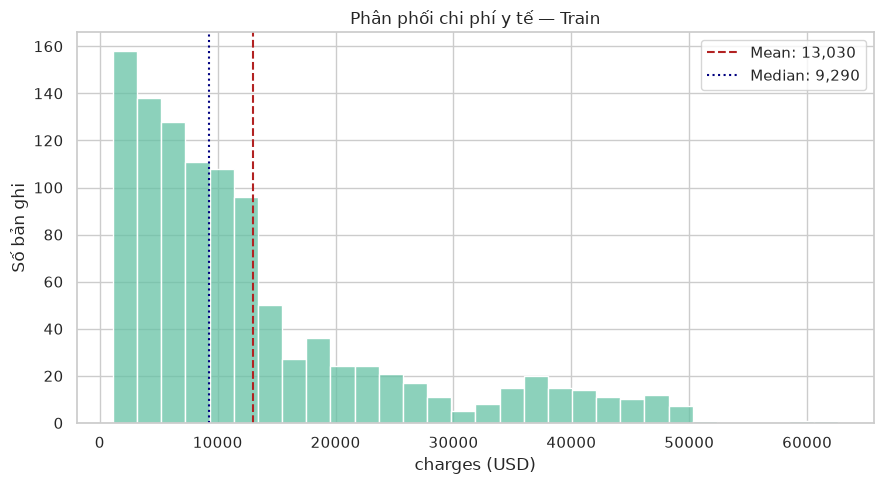

In [2]:
mean_charges = train["charges"].mean()
median_charges = train["charges"].median()
print(f"Trung bình: {mean_charges:,.2f} USD")
print(f"Trung vị: {median_charges:,.2f} USD")
print(f"Độ lệch (skewness): {train['charges'].skew():.2f}")

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=train, x="charges", bins=30, ax=ax)
ax.axvline(mean_charges, color="firebrick", linestyle="--", label=f"Mean: {mean_charges:,.0f}")
ax.axvline(median_charges, color="navy", linestyle=":", label=f"Median: {median_charges:,.0f}")
ax.set(title="Phân phối chi phí y tế — Train", xlabel="charges (USD)", ylabel="Số bản ghi")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "eda_charges_distribution.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**Nhận xét:** `charges` lệch phải (skewness khoảng 1,51), trung bình khoảng 13.030 USD cao hơn trung vị khoảng 9.290 USD. Phần lớn bản ghi có chi phí thấp hơn các trường hợp ở đuôi phải. Có thể thử biến đổi log target khi xây mô hình, nhưng phải so sánh bằng CV và đánh giá sai số trên thang USD.

## 3.5.2. Phân tích mối quan hệ giữa các thuộc tính và chi phí
### Phân bố các thuộc tính
Xem phân phối biến số và số lượng từng nhóm để có bối cảnh khi so sánh chi phí. `children` là biến đếm nên dùng các mốc nguyên.

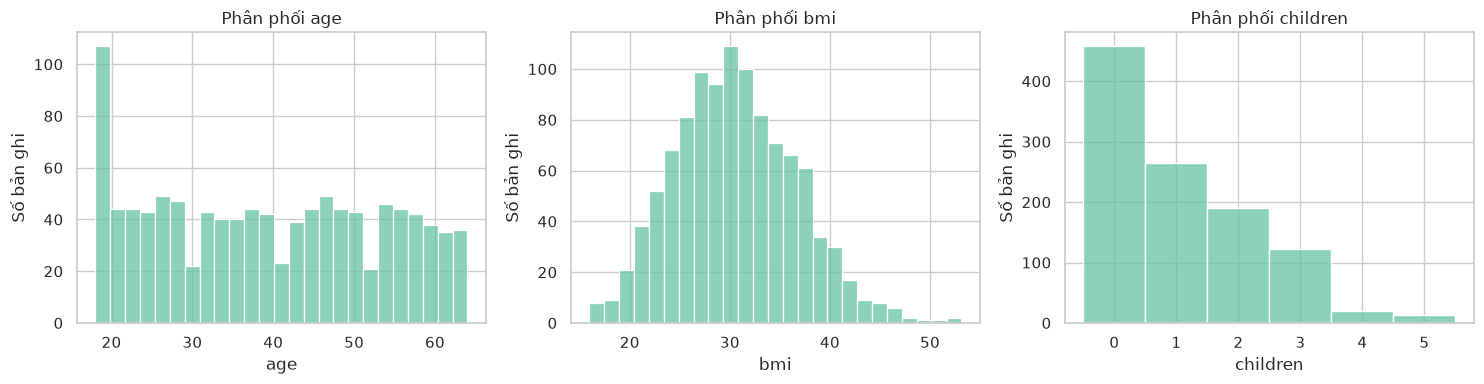

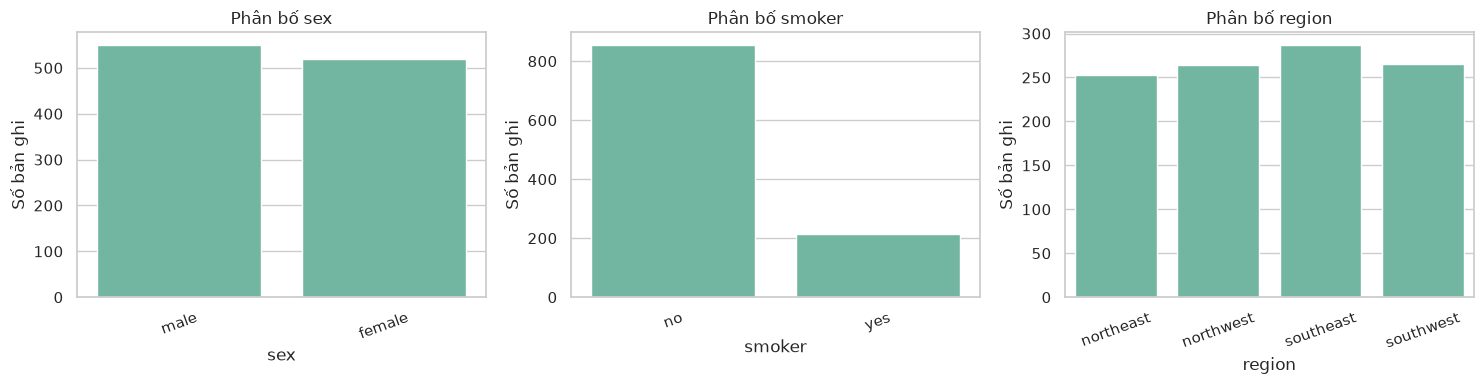

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(["age", "bmi", "children"], axes):
    sns.histplot(data=train, x=col, bins=25, discrete=(col == "children"), ax=ax)
    if col == "children":
        ax.set_xticks(sorted(train[col].unique()))
    ax.set_title(f"Phân phối {col}")
    ax.set_ylabel("Số bản ghi")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(categorical, axes):
    sns.countplot(data=train, x=col, ax=ax)
    ax.set_title(f"Phân bố {col}")
    ax.set_ylabel("Số bản ghi")
    ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout()
plt.show()
plt.close(fig)

### Tình trạng hút thuốc và chi phí
So sánh boxplot và thống kê nhóm. Đây là mối liên hệ quan sát được, không phải ước lượng tác động nhân quả.

,count,mean,median,std
smoker,,,,
no,855,8498.48,7348.14,6075.68
yes,214,31135.93,33391.68,11284.98


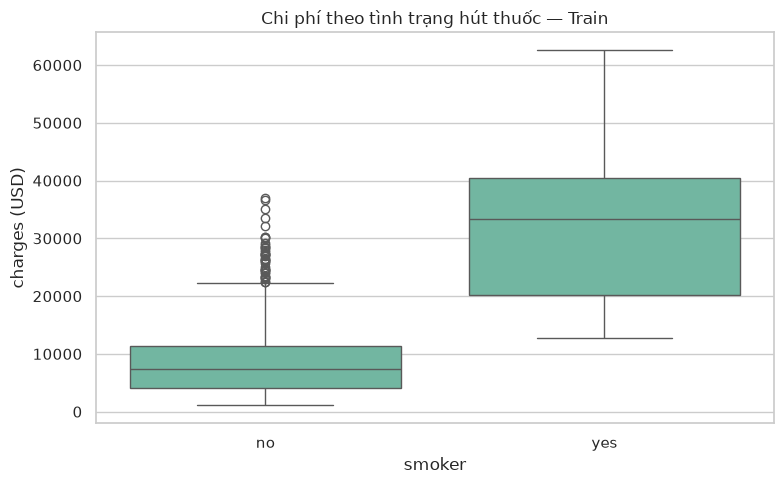

In [4]:
display(train.groupby("smoker")["charges"].agg(["count", "mean", "median", "std"]).round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=train, x="smoker", y="charges", order=["no", "yes"], ax=ax)
ax.set(title="Chi phí theo tình trạng hút thuốc — Train", xlabel="smoker", ylabel="charges (USD)")
fig.tight_layout()
fig.savefig(FIGURES / "eda_smoker_vs_charges.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**Nhận xét:** Train có 214 bản ghi hút thuốc và 855 không hút thuốc. Chi phí trung bình của hai nhóm lần lượt khoảng 31.136 và 8.498 USD; trung vị lần lượt khoảng 33.392 và 7.348 USD. Khác biệt giữa hai nhóm rõ trên cả trung bình và trung vị.

### Các thuộc tính còn lại và chi phí
Scatterplot cho `age`, `bmi`, tô màu theo `smoker`. Với `sex`, `region` và biến đếm `children`, dùng boxplot để so sánh phân phối theo từng nhóm.

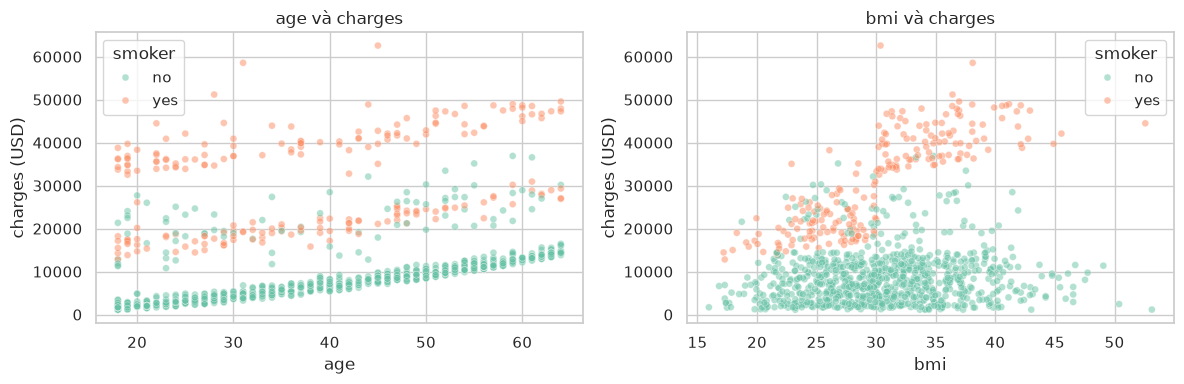

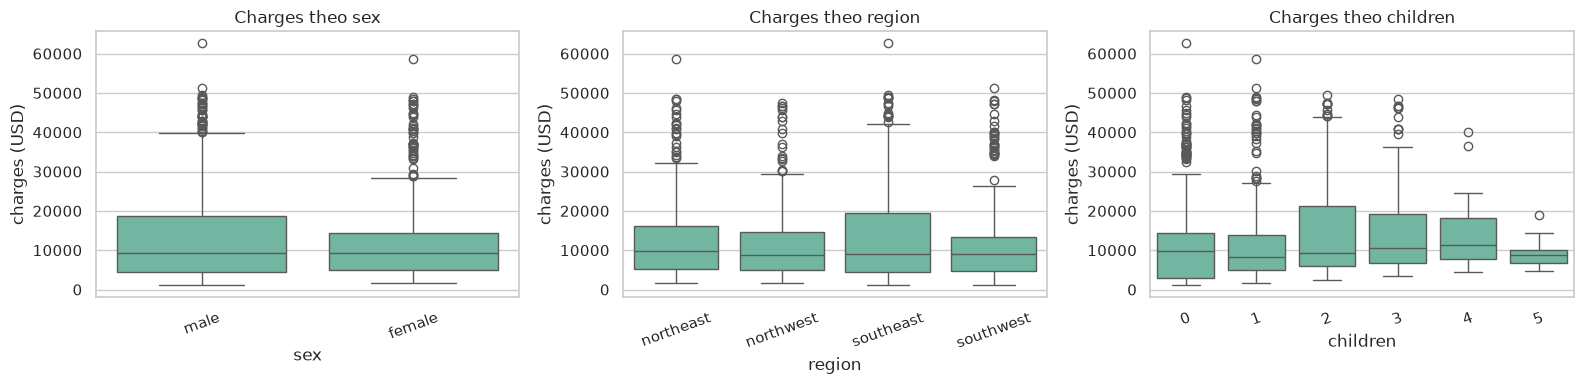

Chi phí theo sex:


,count,mean,median
sex,,,
female,519,12305.47,9411.00
male,550,13714.09,9289.08


Chi phí theo region:


,count,mean,median
region,,,
northeast,253,13241.15,9875.68
northwest,264,11907.34,8749.24
southeast,287,14554.66,9058.73
southwest,265,12296.42,8968.33


Chi phí theo children:


,count,mean,median
children,,,
0,458,11975.55,9856.95
1,265,12419.66,8342.91
2,191,15212.64,9225.26
3,122,15033.59,10651.60
4,19,14915.32,11299.34
5,14,9298.06,8781.31


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col, ax in zip(["age", "bmi"], axes):
    sns.scatterplot(data=train, x=col, y="charges", hue="smoker", alpha=0.5, s=25, ax=ax)
    ax.set_title(f"{col} và charges")
    ax.set_ylabel("charges (USD)")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for col, ax in zip(["sex", "region", "children"], axes):
    sns.boxplot(data=train, x=col, y="charges", ax=ax)
    ax.set_title(f"Charges theo {col}")
    ax.set_ylabel("charges (USD)")
    ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout()
plt.show()
plt.close(fig)

for col in ["sex", "region", "children"]:
    print(f"Chi phí theo {col}:")
    display(train.groupby(col)["charges"].agg(["count", "mean", "median"]).round(2))

**Nhận xét:** biểu đồ tuổi cho thấy các dải chi phí tăng theo tuổi. Quan hệ BMI–chi phí khác nhau giữa nhóm hút thuốc và không hút thuốc, gợi ý cần thử mô hình có thể khai thác tương tác. Trung vị chi phí hai nhóm giới tính gần nhau (khoảng 9.411 và 9.289 USD); trung bình theo vùng dao động khoảng 11.907–14.555 USD. Không kết luận mức độ quan trọng của đặc trưng chỉ từ các so sánh riêng lẻ; chú ý số lượng quan sát khi so sánh các nhóm `children`.

## 3.5.3. Phân tích tương quan giữa các biến
Tính Pearson cho các cột số. Không gán mã số tùy ý cho biến phân loại để đưa vào heatmap. Tương quan đo liên hệ tuyến tính, không thể hiện đầy đủ quan hệ phi tuyến hoặc tương tác.

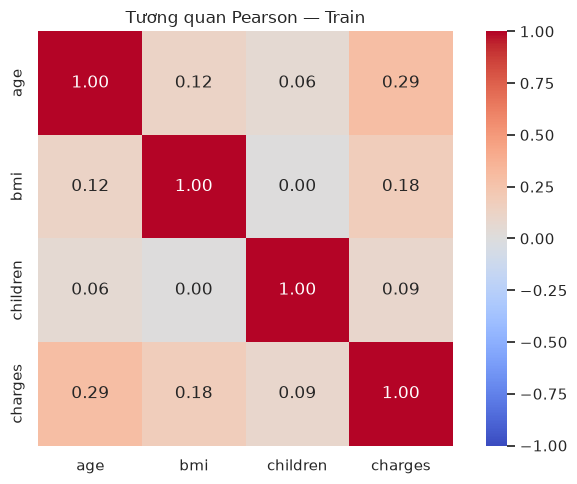

,Tương quan với charges
age,0.290
bmi,0.178
children,0.086


In [6]:
correlation = train[numeric].corr(method="pearson")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Tương quan Pearson — Train")
fig.tight_layout()
fig.savefig(FIGURES / "eda_correlation_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
display(correlation["charges"].drop("charges").round(3).rename("Tương quan với charges").to_frame())

**Nhận xét:** `age`, `bmi` và `children` có tương quan Pearson với `charges` lần lượt khoảng 0,290; 0,178 và 0,086. Các tương quan tuyến tính này không lớn; không dùng chúng làm căn cứ duy nhất để loại đặc trưng. Các cặp đặc trưng số trong heatmap cũng không thể hiện tương quan tuyến tính cao.

## 3.5.4. Tổng hợp nhận xét và đặc điểm nổi bật của dữ liệu
- Chi phí lệch phải, có các trường hợp chi phí cao; giữ lại vì chưa có bằng chứng là dữ liệu sai.
- `smoker` có khác biệt chi phí rõ giữa các nhóm. Tuổi và BMI có quan hệ với chi phí cần được mô hình khai thác, có thể bao gồm tương tác.
- Giữ các đặc trưng hiện tại; so sánh mô hình tuyến tính và mô hình cây bằng CV trên Train để đánh giá khả năng dự đoán.
- Encoding/scaling phải fit trong từng fold CV qua pipeline. Nếu thử biến đổi target, vẫn đánh giá sai số trên thang USD. Chưa lựa chọn mô hình dựa vào EDA.

**Ba ảnh được lưu** trong `results/eda/figures/`:
1. `eda_charges_distribution.png`
2. `eda_smoker_vs_charges.png`
3. `eda_correlation_heatmap.png`

Không xuất bảng CSV. Các bảng và biểu đồ bổ sung nằm trong notebook; chạy lại sẽ cập nhật ba ảnh trên. Test được giữ cho đánh giá cuối cùng.